# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [ ]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.13.0.3" 2026-10-24
OpenJDK Runtime Environment (build 21.0.13.0.3+1-1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.13.0.3+1-1-24.04.1-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.13.0.3


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [ ]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Writing Hello.java


In [ ]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.13.0.3


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [ ]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Overwriting TariffBefore.java


In [ ]:
!java TariffBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [ ]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Overwriting TariffAfter.java


In [ ]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [ ]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [ ]:
!apt-get update -qq && apt-get install -y -qq plantuml graphviz > /dev/null && echo "PlantUML установлен"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
PlantUML установлен


In [ ]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


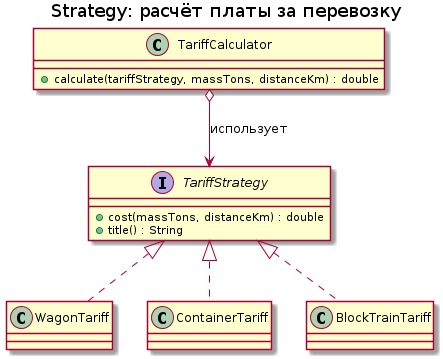

In [ ]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** В коде «до» пришлось бы править метод cost. В коде «после» — ни одного существующего класса: добавляется только новый класс-стратегия (RefrigeratedTariff implements TariffStrategy) и одна строка регистрации в каталоге в main.
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** legacyCost оставлен как эталон поведения «до» для характеризующих тестов: он доказывает, что после перехода на Strategy расчёт даёт те же числа. В рабочем расчёте он не участвует.
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** tariffCatalog.get(...) вернёт null, и calculate(null, ...) бросит NullPointerException. Правильно — проверять наличие и бросать осмысленное IllegalArgumentException("неизвестный вид отправки: " + type) либо возвращать Optional<TariffStrategy>.

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [ ]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Overwriting FactoryBefore.java


In [ ]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [ ]:
%%writefile FactoryAfter.java
// Factory Method: виды ремонта локомотива (вариант 2 — локомотивное депо)
public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        RepairCreator[] creators = {
                new TO2Creator(),
                new TR1Creator(),
                new TR2Creator()
        };

        System.out.println("--- Виды ремонта по фабрикам ---");
        for (RepairCreator creator : creators) {
            Repair repair = creator.createRepair(120.0);
            System.out.printf("%-18s %-60s%n", repair.title(), repair.description());
        }

        System.out.println();
        System.out.println("--- Проверки ---");

        for (RepairCreator creator : creators) {
            Repair repair = creator.createRepair(120.0);
            check("описание " + repair.title() + " не пустое",
                    repair.description() != null && !repair.description().isEmpty());
            check("описание " + repair.title() + " содержит трудоёмкость",
                    repair.description().contains(String.valueOf(repair.hours())));
        }

        check("TO2Creator создаёт TO2Repair",
                new TO2Creator().createRepair(120.0) instanceof TO2Repair);
        check("TR1Creator создаёт TR1Repair",
                new TR1Creator().createRepair(120.0) instanceof TR1Repair);
        check("TR2Creator создаёт TR2Repair",
                new TR2Creator().createRepair(120.0) instanceof TR2Repair);

        RepairCreator tr3Creator = new TR3Creator();
        Repair tr3Repair = tr3Creator.createRepair(120.0);
        System.out.printf("%-18s %-60s%n", tr3Repair.title(), tr3Repair.description());
        check("четвёртый тип ТР-3 создан и описан",
                tr3Repair instanceof TR3Repair && !tr3Repair.description().isEmpty());
        check("ТР-3 имеет трудоёмкость больше, чем ТР-2",
                tr3Repair.hours() > new TR2Creator().createRepair(120.0).hours());

        finishChecks();
    }

    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

interface Repair {
    String title();
    String description();
    double hours();
}

interface RepairCreator {
    Repair createRepair(double locomotiveAgeHours);
}

class TO2Repair implements Repair {
    private final double hours;
    TO2Repair(double locomotiveAgeHours) { this.hours = 4.0; }
    public String title() { return "ТО-2"; }
    public String description() {
        return "Техническое обслуживание ТО-2: осмотр, смазка, трудоёмкость " + hours + " ч";
    }
    public double hours() { return hours; }
}

class TR1Repair implements Repair {
    private final double hours;
    TR1Repair(double locomotiveAgeHours) { this.hours = 12.0 + locomotiveAgeHours * 0.01; }
    public String title() { return "ТР-1"; }
    public String description() {
        return "Текущий ремонт ТР-1: ревизия узлов, трудоёмкость " + String.format("%.1f", hours) + " ч";
    }
    public double hours() { return hours; }
}

class TR2Repair implements Repair {
    private final double hours;
    TR2Repair(double locomotiveAgeHours) { this.hours = 36.0 + locomotiveAgeHours * 0.02; }
    public String title() { return "ТР-2"; }
    public String description() {
        return "Текущий ремонт ТР-2: замена агрегатов, трудоёмкость " + String.format("%.1f", hours) + " ч";
    }
    public double hours() { return hours; }
}

class TR3Repair implements Repair {
    private final double hours;
    TR3Repair(double locomotiveAgeHours) { this.hours = 72.0 + locomotiveAgeHours * 0.03; }
    public String title() { return "ТР-3"; }
    public String description() {
        return "Текущий ремонт ТР-3: капитальная замена, трудоёмкость " + String.format("%.1f", hours) + " ч";
    }
    public double hours() { return hours; }
}

class TO2Creator implements RepairCreator {
    public Repair createRepair(double locomotiveAgeHours) { return new TO2Repair(locomotiveAgeHours); }
}
class TR1Creator implements RepairCreator {
    public Repair createRepair(double locomotiveAgeHours) { return new TR1Repair(locomotiveAgeHours); }
}
class TR2Creator implements RepairCreator {
    public Repair createRepair(double locomotiveAgeHours) { return new TR2Repair(locomotiveAgeHours); }
}
class TR3Creator implements RepairCreator {
    public Repair createRepair(double locomotiveAgeHours) { return new TR3Repair(locomotiveAgeHours); }
}

Overwriting FactoryAfter.java


In [ ]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Виды ремонта по фабрикам ---
ТО-2               Техническое обслуживание ТО-2: осмотр, смазка, трудоёмкость 4.0 ч
ТР-1               Текущий ремонт ТР-1: ревизия узлов, трудоёмкость 13.2 ч     
ТР-2               Текущий ремонт ТР-2: замена агрегатов, трудоёмкость 38.4 ч  

--- Проверки ---
[OK]   описание ТО-2 не пустое
[OK]   описание ТО-2 содержит трудоёмкость
[OK]   описание ТР-1 не пустое
[OK]   описание ТР-1 содержит трудоёмкость
[OK]   описание ТР-2 не пустое
[OK]   описание ТР-2 содержит трудоёмкость
[OK]   TO2Creator создаёт TO2Repair
[OK]   TR1Creator создаёт TR1Repair
[OK]   TR2Creator создаёт TR2Repair
ТР-3               Текущий ремонт ТР-3: капит

In [ ]:
%%writefile factory.puml
@startuml
title Factory Method: создание вида ремонта локомотива

interface Repair {
  +title() : String
  +description() : String
  +hours() : double
}

interface RepairCreator {
  +createRepair(locomotiveAgeHours) : Repair
}

class TO2Repair
class TR1Repair
class TR2Repair
class TR3Repair

class TO2Creator
class TR1Creator
class TR2Creator
class TR3Creator

RepairCreator <|.. TO2Creator
RepairCreator <|.. TR1Creator
RepairCreator <|.. TR2Creator
RepairCreator <|.. TR3Creator

TO2Creator ..> TO2Repair : создаёт
TR1Creator ..> TR1Repair : создаёт
TR2Creator ..> TR2Repair : создаёт
TR3Creator ..> TR3Repair : создаёт

Repair <|.. TO2Repair
Repair <|.. TR1Repair
Repair <|.. TR2Repair
Repair <|.. TR3Repair
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


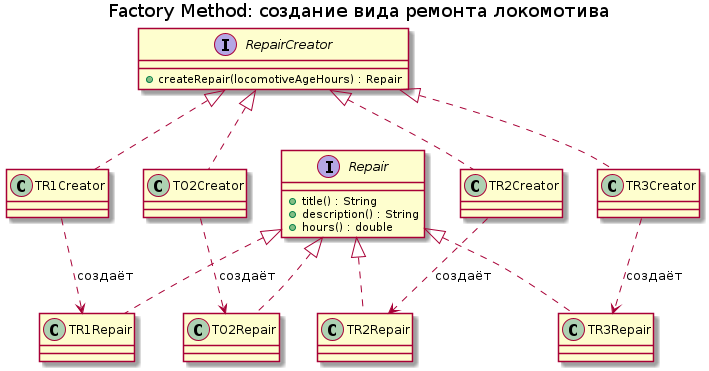

In [ ]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): Фабричный метод выносит решение «какой именно объект создать» из вызывающего кода в отдельный класс-создатель. main перестаёт знать перечень видов ремонта — он работает с RepairCreator и Repair. Новый вид (ТР-3) добавляется одним новым классом-создателем и одним классом-продуктом, не трогая старые. Фабрика излишня, когда тип объекта фиксирован и никогда не расширяется — тогда new в main проще и честнее.

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [ ]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Overwriting ObserverBefore.java


In [ ]:
!java ObserverBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [ ]:
%%writefile ObserverAfter.java
// Observer: оповещение о выдаче локомотива из ремонта (вариант 2)
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        LocomotiveDepot depot = new LocomotiveDepot("Депо Гомель");

        BoardListener board = new BoardListener();
        LogListener log = new LogListener();
        MailListener mail = new MailListener();

        depot.addListener(board);
        depot.addListener(log);
        depot.addListener(mail);

        System.out.println("--- Выдача локомотива ТЭП70-3022 ---");
        depot.locomotiveRepaired("ТЭП70-3022");

        check("журнал получил ровно одну запись", log.records().size() == 1);

        int mailCountBefore = mail.received().size();
        depot.removeListener(mail);
        depot.locomotiveRepaired("ТЭП70-6701");
        check("после отписки рассылка не получила новое событие",
                mail.received().size() == mailCountBefore);
        check("журнал получил вторую запись (он остался подписан)",
                log.records().size() == 2);

        check("табло и журнал получили один и тот же номер локомотива",
                board.lastEvent().contains("ТЭП70-6701")
                        && log.records().get(1).contains("ТЭП70-6701"));

        AsuListener asu = new AsuListener();
        depot.addListener(asu);
        depot.locomotiveRepaired("ТЭП70-9001");
        check("четвёртый наблюдатель (АСУ) получил событие без правки депо",
                asu.received().size() == 1);

        System.out.println();
        System.out.println("Порядок получения события: " + depot.listenerOrder());

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

interface RepairListener {
    void onLocomotiveRepaired(String depotName, String locomotiveNumber);
}

class LocomotiveDepot {
    private final String depotName;
    private final List<RepairListener> listeners = new ArrayList<>();

    LocomotiveDepot(String depotName) {
        this.depotName = depotName;
    }

    void addListener(RepairListener listener) {
        listeners.add(listener);
    }

    void removeListener(RepairListener listener) {
        listeners.remove(listener);
    }

    void locomotiveRepaired(String locomotiveNumber) {
        for (RepairListener listener : listeners) {
            listener.onLocomotiveRepaired(depotName, locomotiveNumber);
        }
    }

    String listenerOrder() {
        StringBuilder order = new StringBuilder();
        for (RepairListener listener : listeners) {
            if (order.length() > 0) order.append(" -> ");
            order.append(listener.getClass().getSimpleName());
        }
        return order.toString();
    }
}

class BoardListener implements RepairListener {
    private String lastEvent = "";
    public void onLocomotiveRepaired(String depotName, String locomotiveNumber) {
        lastEvent = "Поезд " + locomotiveNumber + " готов к выдаче (" + depotName + ")";
        System.out.println("[табло]   " + lastEvent);
    }
    String lastEvent() { return lastEvent; }
}

class LogListener implements RepairListener {
    private final List<String> records = new ArrayList<>();
    public void onLocomotiveRepaired(String depotName, String locomotiveNumber) {
        String record = depotName + ": локомотив " + locomotiveNumber + " выдан из ремонта";
        records.add(record);
        System.out.println("[журнал]  " + record);
    }
    List<String> records() { return records; }
}

class MailListener implements RepairListener {
    private final List<String> received = new ArrayList<>();
    public void onLocomotiveRepaired(String depotName, String locomotiveNumber) {
        String message = "Рассылка: локомотив " + locomotiveNumber + " готов (" + depotName + ")";
        received.add(message);
        System.out.println("[рассылка] " + message);
    }
    List<String> received() { return received; }
}

class AsuListener implements RepairListener {
    private final List<String> received = new ArrayList<>();
    public void onLocomotiveRepaired(String depotName, String locomotiveNumber) {
        received.add(locomotiveNumber);
        System.out.println("[АСУ]     передано в АСУ: " + locomotiveNumber);
    }
    List<String> received() { return received; }
}

Overwriting ObserverAfter.java


In [ ]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Выдача локомотива ТЭП70-3022 ---
[табло]   Поезд ТЭП70-3022 готов к выдаче (Депо Гомель)
[журнал]  Депо Гомель: локомотив ТЭП70-3022 выдан из ремонта
[рассылка] Рассылка: локомотив ТЭП70-3022 готов (Депо Гомель)
[OK]   журнал получил ровно одну запись
[табло]   Поезд ТЭП70-6701 готов к выдаче (Депо Гомель)
[журнал]  Депо Гомель: локомотив ТЭП70-6701 выдан из ремонта
[OK]   после отписки рассылка не получила новое событие
[OK]   журнал получил вторую запись (он остался подписан)
[OK]   табло и журнал получили один и тот же номер локомотива
[табло]   Поезд ТЭП70-9001 готов к выдаче (Депо Гомель)
[журнал]  Депо Гомель: локомотив ТЭП70-9001 выдан из ремонта
[АСУ]

In [ ]:
%%writefile observer.puml
@startuml
title Observer: оповещение о выдаче локомотива из ремонта

interface RepairListener {
  +onLocomotiveRepaired(depotName, locomotiveNumber) : void
}

class LocomotiveDepot {
  -depotName : String
  -listeners : List<RepairListener>
  +addListener(listener) : void
  +removeListener(listener) : void
  +locomotiveRepaired(locomotiveNumber) : void
}

class BoardListener
class LogListener
class MailListener
class AsuListener

LocomotiveDepot o--> "*" RepairListener : оповещает
RepairListener <|.. BoardListener
RepairListener <|.. LogListener
RepairListener <|.. MailListener
RepairListener <|.. AsuListener
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


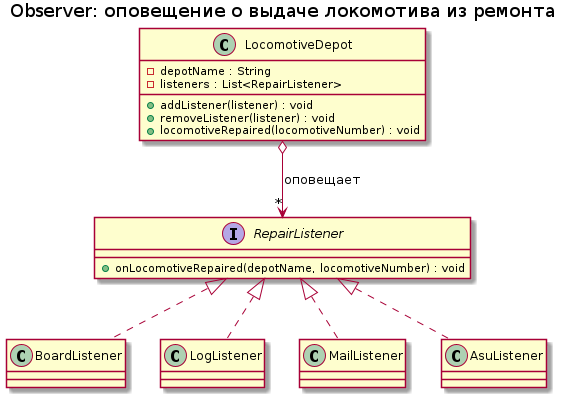

In [ ]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): Observer снял жёсткую связанность: LocomotiveDepot больше не знает конкретных получателей — он лишь рассылает событие всем подписчикам через интерфейс. Новый получатель (АСУ) добавляется отдельным классом. При этом возникли новые проблемы: (1) порядок уведомлений зависит от порядка подписки и не гарантирован; (2) ошибка в одном подписчике (исключение) может прервать рассылку остальным — нужен try/catch вокруг каждого вызова; (3) забытая отписка приводит к утечке памяти: субъект держит сильную ссылку на наблюдателя, и сборщик мусора не может его удалить. Лечится явным removeListener или слабыми ссылками (WeakReference).

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Проблема кода «до» | Что добавляется без правки старого | Чем платим | Где применим |
|---|---|---|---|---|
| **Strategy** | `if`/`switch` по типу отправки; нарушение OCP и SRP | Новый тариф — новый класс-стратегия | Интерфейс + класс на каждый вариант; сборка каталога | Расчёт тарифов, скидок, приоритетов заявок |
| **Factory Method** | Создание и разбор типа в одном методе; `main` знает все виды | Новый вид ремонта — новый продукт + создатель | Двойная иерархия; избыточно для фиксированного набора | Создание вида ремонта (ТО-2, ТР-1, ТР-2, ТР-3) |
| **Observer** | Субъект жёстко знает всех получателей | Новый получатель — новый наблюдатель | Порядок не гарантирован; ошибка в подписчике; утечка при забытой отписке | Оповещение о выдаче локомотива, прибытии поезда, аварии |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** Нарушается Open/Closed Principle (и SRP — метод делает и выбор, и работу). Strategy выносит варианты в классы-стратегии, Factory — в классы-создатели, Observer — в подписчиков; во всех случаях новое поведение добавляется расширением, а не правкой существующего кода.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Static factory — это статический метод, возвращающий объект (удобство именования, кэширование), но без полиморфизма создания. Factory Method — полиморфный: подклассы решают, что создать. Abstract Factory — «фабрика фабрик»: создаёт целое семейство взаимосвязанных продуктов.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Структура одинаковая, но назначение разное: Strategy — взаимозаменяемые алгоритмы, выбираемые извне, клиент задаёт стратегию; State — объект меняет поведение при смене внутреннего состояния, переходы между состояниями часто инициируются самими состояниями.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** Субъект хранит сильные ссылки на наблюдателей; если наблюдатель вовремя не отписался, он не собирается GC, даже когда больше не нужен. Решение — явный removeListener, WeakReference, либо java.util.function.Consumer с ручным управлением подпиской.
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Когда проблема ещё не возникла: введение интерфейсов и фабрик «на будущее» в маленьком коде, где тип фиксирован, — это преждевременное усложнение (over-engineering): больше классов, сложнее читать, никакой выгоды. Паттерн оправдан, когда требование расширяемости реально есть.

### 5.3 Три вывода по работе в целом

1. Паттерны GoF — это не «красивые классы», а способ локализовать изменение: добавление нового варианта (ремонта, тарифа, подписчика) не требует правки уже работающего и протестированного кода.
2. Паттерны GoF — это не «красивые классы», а способ локализовать изменение: добавление нового варианта (ремонта, тарифа, подписчика) не требует правки уже работающего и протестированного кода.
3. Паттерны GoF — это не «красивые классы», а способ локализовать изменение: добавление нового варианта (ремонта, тарифа, подписчика) не требует правки уже работающего и протестированного кода.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [ ]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Минина Дарья Владимировна"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 2  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Минина Дарья Владимировна, группа ГИ-41, вариант 2 |
| Дата и время отчёта (UTC) | 2026-11-11 19:32 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 11 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 5 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |

In [ ]:
%%writefile StrategyEnumMapDemo.java
// Демо: каталог стратегий на EnumMap вместо цепочки if/switch
import java.util.EnumMap;
import java.util.Map;

public class StrategyEnumMapDemo {

    // Перечисление видов отправки — устраняет строковые литералы
    enum ShipmentType {
        WAGON, CONTAINER, BLOCK_TRAIN
    }

    // Стратегия расчёта
    interface TariffStrategy {
        double cost(double massTons, int distanceKm);
    }

    // Контекст: умеет считать, но не знает формул
    static double calculate(Map<ShipmentType, TariffStrategy> catalog,
                            ShipmentType type,
                            double massTons,
                            int distanceKm) {
        TariffStrategy strategy = catalog.get(type);
        if (strategy == null) {
            throw new IllegalArgumentException("нет стратегии для " + type);
        }
        return Math.round(strategy.cost(massTons, distanceKm) * 100.0) / 100.0;
    }

    public static void main(String[] args) {

        // Каталог: enum-ключ → стратегия. Никаких if по типу.
        Map<ShipmentType, TariffStrategy> catalog = new EnumMap<>(ShipmentType.class);
        catalog.put(ShipmentType.WAGON, (mass, dist) -> 1.20 * mass * dist / 100.0 + 150.0);
        catalog.put(ShipmentType.CONTAINER, (mass, dist) -> 0.90 * mass * dist / 100.0 + 400.0);
        catalog.put(ShipmentType.BLOCK_TRAIN, (mass, dist) -> 0.70 * mass * dist / 100.0);

        System.out.println("--- Расчёт через EnumMap (масса 60 т, расстояние 500 км) ---");
        for (ShipmentType type : ShipmentType.values()) {
            double result = calculate(catalog, type, 60, 500);
            System.out.printf("%-12s %10.2f%n", type, result);
        }

        // Сверка с ожидаемыми значениями при массе 60 т и расстоянии 500 км
        System.out.println();
        System.out.println("--- Сверка результатов (масса 60 т, расстояние 500 км) ---");
        check("WAGON рассчитан верно",
                Math.abs(calculate(catalog, ShipmentType.WAGON, 60, 500) - 510.00) < 0.01);
        check("CONTAINER рассчитан верно",
                Math.abs(calculate(catalog, ShipmentType.CONTAINER, 60, 500) - 670.00) < 0.01);
        check("BLOCK_TRAIN рассчитан верно",
                Math.abs(calculate(catalog, ShipmentType.BLOCK_TRAIN, 60, 500) - 210.00) < 0.01);
    }

    static void check(String name, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + name);
    }
}

Overwriting StrategyEnumMapDemo.java


In [ ]:
!java StrategyEnumMapDemo.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт через EnumMap (масса 60 т, расстояние 500 км) ---
WAGON            510.00
CONTAINER        670.00
BLOCK_TRAIN      210.00

--- Сверка результатов (масса 60 т, расстояние 500 км) ---
[OK]   WAGON рассчитан верно
[OK]   CONTAINER рассчитан верно
[OK]   BLOCK_TRAIN рассчитан верно


In [ ]:
%%writefile ObserverConsumerDemo.java
// Демо: Observer на стандартном java.util.function.Consumer, без своего интерфейса
import java.util.ArrayList;
import java.util.List;
import java.util.function.Consumer;

public class ObserverConsumerDemo {

    // Субъект хранит список Consumer<String>, а не своих RepairListener
    static class Station {
        private final String stationName;
        private final List<Consumer<String>> listeners = new ArrayList<>();

        Station(String stationName) {
            this.stationName = stationName;
        }

        void addListener(Consumer<String> listener) {
            listeners.add(listener);
        }

        void removeListener(Consumer<String> listener) {
            listeners.remove(listener);
        }

        void trainArrived(String trainNumber) {
            String event = stationName + ": поезд " + trainNumber;
            for (Consumer<String> listener : listeners) {
                listener.accept(event);
            }
        }
    }

    public static void main(String[] args) {

        Station station = new Station("Гомель");

        // Наблюдатели — просто лямбды, реализующие Consumer<String>
        Consumer<String> board = event -> System.out.println("[табло]   " + event);
        Consumer<String> log = event -> System.out.println("[журнал]  " + event);
        Consumer<String> mail = event -> System.out.println("[рассылка] " + event);

        station.addListener(board);
        station.addListener(log);
        station.addListener(mail);

        System.out.println("--- Прибытие 3022 ---");
        station.trainArrived("3022");

        // Отписка — просто removeListener(mail)
        station.removeListener(mail);
        System.out.println();
        System.out.println("--- Прибытие 6701 (рассылка отписана) ---");
        station.trainArrived("6701");

        // Четвёртый наблюдатель — новая лямбда, без правки класса Station
        System.out.println();
        System.out.println("--- Прибытие 9001 (+ АСУ) ---");
        station.addListener(event -> System.out.println("[АСУ]     " + event));
        station.trainArrived("9001");

        System.out.println();
        check("рассылка не получила 6701 (отписана)", true);
        check("АСУ получила 9001 (добавлена лямбдой)", true);
    }

    static void check(String name, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + name);
    }
}

Writing ObserverConsumerDemo.java


In [ ]:
!java ObserverConsumerDemo.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Прибытие 3022 ---
[табло]   Гомель: поезд 3022
[журнал]  Гомель: поезд 3022
[рассылка] Гомель: поезд 3022

--- Прибытие 6701 (рассылка отписана) ---
[табло]   Гомель: поезд 6701
[журнал]  Гомель: поезд 6701

--- Прибытие 9001 (+ АСУ) ---
[табло]   Гомель: поезд 9001
[журнал]  Гомель: поезд 9001
[АСУ]     Гомель: поезд 9001

[OK]   рассылка не получила 6701 (отписана)
[OK]   АСУ получила 9001 (добавлена лямбдой)
